# 03 · KPIs de monitoring et dashboard

Dernier notebook de la série. Le champion est entraîné (notebook 02), il est mis « en production »
en janvier 2016 et doit scorer les nouveaux prêts chaque mois. La question du monitoring : **à quel
moment, et sur quel signal, aurait-on dû réagir ?**

Tout est calculé par `alm_monitoring.ModelMonitor` à partir de la configuration YAML ; le notebook
exécute une fenêtre pour montrer le mécanisme, puis lit l'historique des 24 fenêtres mensuelles
produit par la CLI (`alm-monitor run --by-period MS`) pour raconter l'histoire.

**Plan**

1. La configuration : 14 KPIs en quatre familles, et leurs seuils
2. Exécuter le monitor sur une fenêtre (janvier 2016 vs référence)
3. L'historique mensuel 2016-2017 : statut par mois
4. Les courbes qui racontent l'histoire (dérive de données, y compris les features métier, de prédictions, performance)
5. La heatmap « tour de contrôle »
6. Chronologie, décision de l'équipe et lien avec le dashboard Dataiku

In [1]:
import json
import warnings

warnings.filterwarnings("ignore")
import logging

logging.getLogger("alm_monitoring").setLevel(logging.ERROR)

import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
import yaml

pio.renderers.default = "notebook+png"  # +png : figure statique visible sur GitHub
pd.set_option("display.max_rows", 30)
pd.set_option("display.width", 160)

from alm_monitoring import ModelMonitor, viz
from alm_monitoring.types import Severity

ROOT = ".."
CONFIG = f"{ROOT}/configs/lending_club_prepayment.yaml"

## 1. La configuration

Le fichier `configs/lending_club_prepayment.yaml` décrit le modèle (cible, score, date, features) et
la liste des KPIs avec leurs seuils. Chaque clé est validée (`MonitoringConfig`) ; une clé inconnue
est rejetée, ce qui évite les fautes de frappe silencieuses sur un seuil.

La liste des features surveillées comprend les 21 features de base **et** les 7 features métier
dérivées par `lc.engineer_features` (notebook 02), même si le champion n'en utilise qu'une partie :
`rate_spread` (écart au taux de marché du mois) est le moteur économique du remboursement anticipé,
il doit être surveillé en tant que tel.

In [2]:
with open(CONFIG) as f:
    cfg = yaml.safe_load(f)

print(
    "Modèle :",
    cfg["model"]["name"],
    "v" + cfg["model"]["version"],
    "| tâche :",
    cfg["model"]["task"],
)
print(
    "Cible  :",
    cfg["model"]["target"],
    "| score :",
    cfg["model"]["prediction"],
    "| date :",
    cfg["model"]["timestamp"],
)
print("Taille minimale d'une fenêtre :", cfg["min_sample_size"], "prêts")

kpis_cfg = pd.DataFrame(
    [
        {
            "kpi": k["name"],
            "actif": k.get("enabled", True),
            "warning": (k.get("thresholds") or {}).get("warning"),
            "critical": (k.get("thresholds") or {}).get("critical"),
            "colonnes": ", ".join(k["columns"])
            if "columns" in k
            else (
                "toutes les features"
                if k["name"]
                in (
                    "schema_conformity",
                    "missing_rate",
                    "unseen_categories_rate",
                    "out_of_range_rate",
                    "psi",
                    "js_distance",
                    "cramers_v",
                )
                else "score / cible"
            ),
            "params": json.dumps(k["params"]) if "params" in k else "",
        }
        for k in cfg["kpis"]
    ]
)
kpis_cfg

Modèle : lending_club_prepayment v2016.01 | tâche : binary_classification
Cible  : prepaid_12m | score : score | date : issue_d
Taille minimale d'une fenêtre : 1000 prêts


,kpi,actif,warning,critical,colonnes,params
0,schema_conformity,True,NaN,NaN,toutes les features,
1,missing_rate,True,0.100,0.200,toutes les features,
2,unseen_categories_rate,True,NaN,NaN,toutes les features,
3,out_of_range_rate,True,NaN,NaN,toutes les features,"{""lower_q"": 0.001, ""upper_q"": 0.999}"
4,psi,True,NaN,NaN,toutes les features,"{""bins"": 10}"
5,js_distance,True,NaN,NaN,toutes les features,
6,ks_test,True,NaN,NaN,"int_rate, fico, dti, loan_amnt, annual_inc, re...",
7,cramers_v,True,NaN,NaN,toutes les features,
8,prediction_drift,True,0.100,0.250,score / cible,
9,auc,True,0.610,0.580,score / cible,


Quand un seuil n'est pas précisé dans le YAML, c'est le **seuil par défaut du KPI** qui s'applique.
La CLI les affiche avec la définition de chaque indicateur :

In [3]:
!alm-monitor list-kpis

auc                       performance       plus bas = pire   warn=0.75 crit=0.7
                          AUC ROC sur la fenêtre courante (pouvoir discriminant).
brier_score               performance       plus haut = pire  warn=0.1 crit=0.15
                          Score de Brier (plus bas est meilleur) ; combine calibration et raffinement.
calibration_error         performance       plus haut = pire  warn=0.03 crit=0.06
                          Expected Calibration Error avec 10 classes de largeur égale. Critique en ALM : une probabilité de remboursement anticipé ou de rétention des dépôts mal calibrée biaise directement les projections de flux, même si le classement (AUC) est intact.
cramers_v                 data_drift        plus haut = pire  warn=0.1 crit=0.3
                          V de Cramér corrigé du biais, issu d'un test d'indépendance du khi-deux entre l'indicateur de fenêtre (référence/courante) et une variable catégorielle.
js_distance               data_drift     

Les 14 KPIs actifs se répartissent en quatre familles, du signal le plus précoce au plus tardif :

| famille | KPIs | disponible… |
|---|---|---|
| qualité des données | `schema_conformity`, `missing_rate`, `unseen_categories_rate`, `out_of_range_rate` | immédiatement |
| dérive des données | `psi`, `js_distance`, `ks_test`, `cramers_v` | immédiatement |
| dérive des prédictions | `prediction_drift` (PSI du score) | immédiatement |
| performance | `auc`, `brier_score`, `calibration_error`, `level_bias`, `performance_degradation` | 12 mois plus tard, quand la cible est connue |

Les seuils de performance sont **ancrés sur le champion** (gradient boosting sur features métier :
AUC hors temps 0,64, Brier 0,127, ECE 0,019)
et non sur des valeurs génériques. Les seuils de `calibration_error` et `level_bias` (2 points =
warning, 4 points = critical) correspondent à l'erreur tolérée sur un taux d'écoulement en ALM.

## 2. Exécuter le monitor sur une fenêtre

On charge les deux datasets scorés produits par l'entraînement :

* `reference.csv` : les 791 538 prêts 2013-2015 avec leur **score hors-pli** (c'est la
  distribution de référence du score, non sur-ajustée) ;
* `current.csv` : les 877 986 prêts 2016-2017 scorés par le champion.

Les deux fichiers contiennent les features de base et les features métier (28 colonnes de
features), ce qui permet au monitor de surveiller `rate_spread`, `loan_to_income`, etc.

Puis on exécute le monitor sur la **première fenêtre de production : janvier 2016**.

In [4]:
reference = pd.read_csv(
    f"{ROOT}/data/processed/lending_club/reference.csv", parse_dates=["issue_d"]
)
current = pd.read_csv(f"{ROOT}/data/processed/lending_club/current.csv", parse_dates=["issue_d"])
janvier_2016 = current[(current["issue_d"] >= "2016-01-01") & (current["issue_d"] < "2016-02-01")]
print(f"référence : {len(reference):,} prêts | janvier 2016 : {len(janvier_2016):,} prêts")

référence : 791,538 prêts | janvier 2016 : 32,366 prêts


In [5]:
monitor = ModelMonitor.from_yaml(CONFIG)
print(f"{len(monitor.kpis)} KPIs chargés :", ", ".join(k.name for k in monitor.kpis))

rapport = monitor.run(reference, janvier_2016, metadata={"window_start": "2016-01-01"})
print("\nSévérité globale :", rapport.overall_severity.value.upper())
resume = rapport.summary()
print("Résultats        :", resume["severity_counts"])
print("Pire par famille :", resume["category_worst_severity"])

14 KPIs chargés : schema_conformity, missing_rate, unseen_categories_rate, out_of_range_rate, psi, js_distance, ks_test, cramers_v, prediction_drift, auc, brier_score, calibration_error, level_bias, performance_degradation



Sévérité globale : WARNING
Résultats        : {'ok': 124, 'warning': 7, 'critical': 0, 'error': 0}
Pire par famille : {'data_drift': 'warning', 'prediction_drift': 'ok', 'performance': 'ok', 'data_quality': 'warning'}


In [6]:
depassements = pd.DataFrame(
    [
        {
            "kpi": r.kpi,
            "colonne": r.column,
            "valeur": round(r.value, 4),
            "sévérité": r.severity.value,
            "seuil warning": r.thresholds.warning if r.thresholds else None,
            "seuil critical": r.thresholds.critical if r.thresholds else None,
        }
        for r in rapport.breaches(Severity.WARNING)
    ]
)
depassements

,kpi,colonne,valeur,sévérité,seuil warning,seuil critical
0,out_of_range_rate,dti,0.0110,warning,0.01,0.05
1,psi,int_rate,0.1717,warning,0.10,0.25
2,psi,rate_spread,0.1212,warning,0.10,0.25
3,js_distance,int_rate,0.1748,warning,0.10,0.20
4,js_distance,rate_spread,0.1469,warning,0.10,0.20
5,js_distance,term_x_rate,0.1085,warning,0.10,0.20
6,ks_test,int_rate,0.1690,warning,0.10,0.20


In [7]:
tableau = rapport.to_dataframe()
print(
    f"{len(tableau)} lignes (une par KPI × colonne), format identique au dataset Dataiku monitoring_kpis"
)
perf = tableau[tableau["category"] == "performance"][
    ["kpi", "value", "severity", "warning_threshold", "critical_threshold"]
]
perf.round(4)

131 lignes (une par KPI × colonne), format identique au dataset Dataiku monitoring_kpis


,kpi,value,severity,warning_threshold,critical_threshold
126,auc,0.6477,ok,0.610,0.580
127,brier_score,0.1152,ok,0.135,0.145
128,calibration_error,0.0046,ok,0.020,0.040
129,level_bias,0.0046,ok,0.020,0.040
130,performance_degradation,-0.0036,ok,0.050,0.100


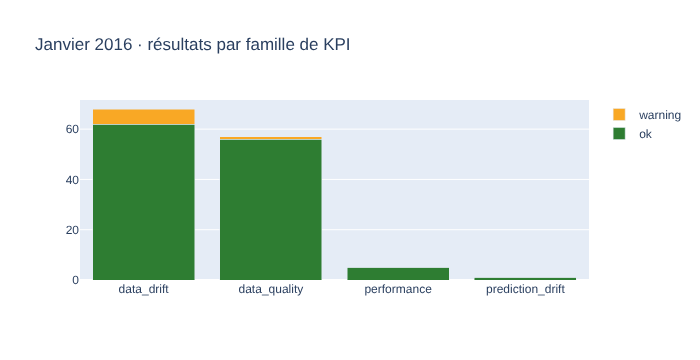

In [8]:
viz.severity_summary(tableau, title="Janvier 2016 · résultats par famille de KPI").show()

**Lecture de janvier 2016.** Le modèle vient d'être déployé et la fenêtre est déjà en **warning**
(7 dépassements) : la distribution de `int_rate` s'est déplacée par rapport à 2013-2015 (PSI ≈ 0,17,
JS et KS concordants), à cause de la baisse des taux sur 2015-2016, et les features métier qui en
dérivent suivent (`rate_spread` PSI 0,12, `term_x_rate` en JS). Les KPIs de performance sont tous
verts : AUC 0,65, ECE et biais de niveau de 0,5 point. À ce stade, rien d'inquiétant : on documente
la dérive de `int_rate` et on continue.

Note : `prediction_drift` et les KPIs de performance de janvier 2016 ne seraient réellement
disponibles qu'en janvier 2017, quand la cible à 12 mois est observée ; dans ce rétro-test, tout
est calculé d'un coup.

## 3. L'historique mensuel 2016-2017

`monitor.run_over_time(reference, current, freq="MS")` produit un rapport par mois ; c'est ce que
la CLI a exécuté pour les 24 fenêtres et stocké dans `reports/lending_club/history.csv` (3 144
lignes = 24 fenêtres × 131 résultats, les features métier surveillées comprises). On relit ce
fichier plutôt que de recalculer (environ 3 minutes).

In [9]:
history = pd.read_csv(f"{ROOT}/reports/lending_club/history.csv")
history["mois"] = pd.to_datetime(history["window_start"]).dt.strftime("%Y-%m")
print(
    history.shape, "|", history["mois"].nunique(), "fenêtres |", history["kpi"].nunique(), "KPIs"
)

rang = {"ok": 0, "warning": 1, "critical": 2, "error": 3}
statut = (
    history.groupby("mois")
    .agg(
        resultats=("kpi", "size"),
        warning=("severity", lambda s: int((s == "warning").sum())),
        critical=("severity", lambda s: int((s == "critical").sum())),
        statut=("severity", lambda s: max(s, key=rang.get)),
    )
    .reset_index()
)
statut["premiers critiques"] = (
    statut["mois"]
    .map(
        history[history["severity"] == "critical"]
        .groupby("mois")
        .apply(
            lambda d: ", ".join((d["kpi"] + "·" + d["column"].fillna("")).str.rstrip("·").head(3))
        )
    )
    .fillna("")
)
statut

(3144, 32) | 24 fenêtres | 14 KPIs


,mois,resultats,warning,critical,statut,premiers critiques
0,2016-01,131,7,0,warning,
1,2016-02,131,7,0,warning,
2,2016-03,131,9,0,warning,
3,2016-04,131,8,0,warning,
4,2016-05,131,11,0,warning,
5,2016-06,131,9,0,warning,
6,2016-07,131,9,0,warning,
7,2016-08,131,14,0,warning,
8,2016-09,131,15,0,warning,
9,2016-10,131,15,1,critical,brier_score


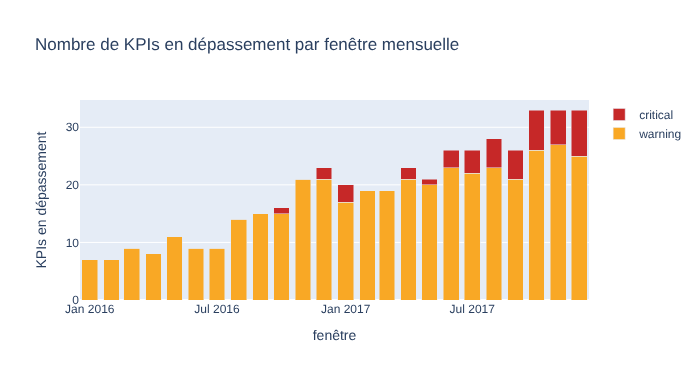

In [10]:
fig = go.Figure()
fig.add_trace(
    go.Bar(x=statut["mois"], y=statut["warning"], name="warning", marker_color="#f9a825")
)
fig.add_trace(
    go.Bar(x=statut["mois"], y=statut["critical"], name="critical", marker_color="#c62828")
)
fig.update_layout(
    barmode="stack",
    title="Nombre de KPIs en dépassement par fenêtre mensuelle",
    yaxis_title="KPIs en dépassement",
    xaxis_title="fenêtre",
    height=380,
)
fig.show()

Le nombre de dépassements monte de **7 à 27 avertissements par mois** sur la période. Le **premier
critical apparaît en octobre 2016** (score de Brier 0,146), suivi d'un pic isolé de `rate_spread` en
décembre 2016 et d'un mois de janvier 2017 où les trois KPIs de calibration (Brier, ECE, biais de
niveau) sont critiques en même temps ; le statut repasse en warning en février-mars 2017, puis à
partir d'**avril 2017 le modèle est en critical en continu**, d'abord à cause de `application_type`,
puis de `int_rate` à partir de juin 2017, avec un nombre de KPIs critiques qui grimpe jusqu'à 8 en
décembre 2017.

## 4. Les courbes qui racontent l'histoire

Les fonctions de `alm_monitoring.viz` prennent l'historique au format long et tracent un KPI avec
ses seuils (points colorés par sévérité). On regarde dans l'ordre où l'équipe les aurait vus :
d'abord la dérive des données, puis celle des prédictions, enfin la performance.

### 4a. Dérive des données : `int_rate`, `application_type` et la feature métier `rate_spread`

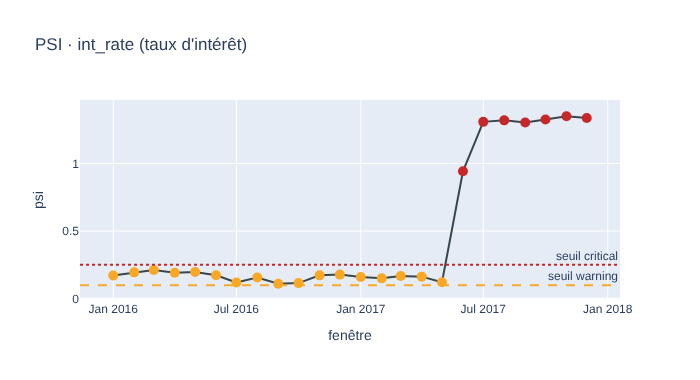

In [11]:
viz.kpi_timeseries(
    history, "psi", column="int_rate", title="PSI · int_rate (taux d'intérêt)"
).show()

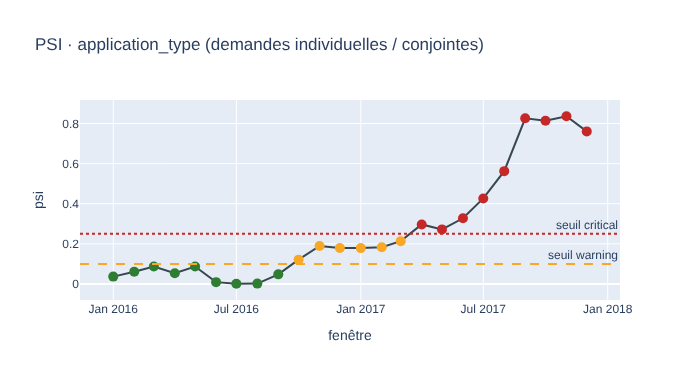

In [12]:
viz.kpi_timeseries(
    history,
    "psi",
    column="application_type",
    title="PSI · application_type (demandes individuelles / conjointes)",
).show()

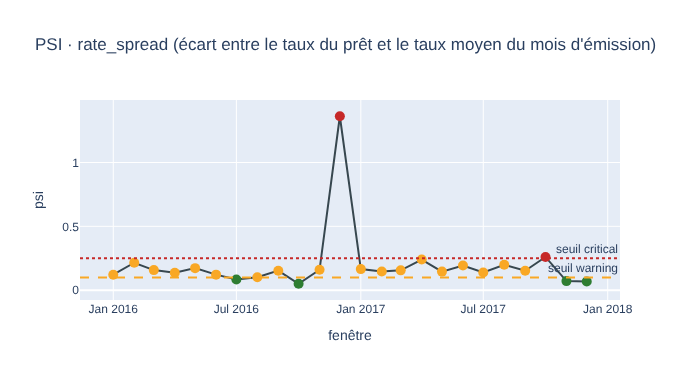

In [13]:
viz.kpi_timeseries(
    history,
    "psi",
    column="rate_spread",
    title="PSI · rate_spread (écart entre le taux du prêt et le taux moyen du mois d'émission)",
).show()

**`int_rate`** est en warning dès le premier mois (PSI 0,11-0,21, conséquence des baisses de taux
2015-2016) puis **explose en juin 2017 (PSI 0,94) et dépasse 1,3 à partir de juillet** : Lending Club
a changé sa grille tarifaire et le taux d'intérêt des nouveaux prêts ne ressemble plus du tout à
celui de la référence. Comme `int_rate` est une feature majeure du modèle, celui-ci reçoit des
entrées hors du domaine sur lequel il a appris.

**`application_type`** monte progressivement : les demandes conjointes (*Joint App*), quasi absentes
en 2013-2015, deviennent une modalité significative ; le PSI franchit le seuil critique en avril
2017 (0,30) et dépasse 0,8 en fin d'année. C'est une dérive de population « nouvelle clientèle ».

**`rate_spread`**, la feature métier, raconte autre chose que `int_rate` : étant calculée **par
rapport au taux moyen du mois**, elle est insensible au niveau général des taux et ne « voit » pas
la baisse de 2015-2016 ni, à elle seule, le changement de niveau de 2017. Elle reste en warning
modéré (PSI 0,05-0,24) avec deux exceptions : un pic isolé en **décembre 2016** (PSI 1,36, un mois
d'émission atypique) et une **dérive à l'automne 2017** (PSI 0,26 en octobre 2017, au-dessus du
seuil critique de 0,25). C'est la signature du **changement de grille tarifaire** : ce n'est plus
seulement le niveau des taux qui bouge, c'est leur **dispersion autour du marché**, autrement dit
l'écart au marché de chaque prêt, celui-là même qui pilote l'incitation à refinancer. Un prêt émis à
l'automne 2017 n'a plus la même « distance au marché » qu'un prêt de la référence, et la feature la
plus importante du champion après `total_acc` (notebook 02) est désormais hors de son domaine
d'apprentissage.

### 4b. Dérive des prédictions : le signal précoce

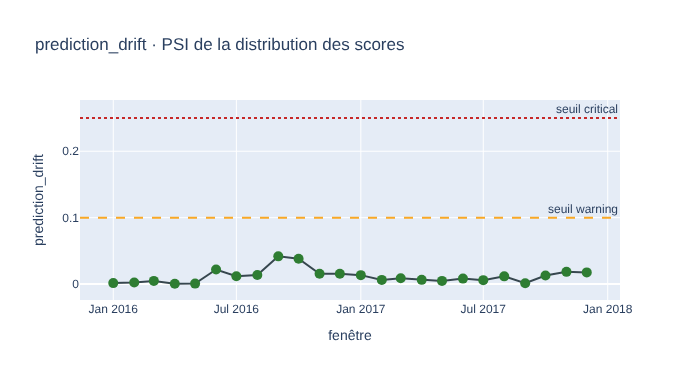

In [14]:
viz.kpi_timeseries(
    history,
    "prediction_drift",
    column="score",
    title="prediction_drift · PSI de la distribution des scores",
).show()

Le `prediction_drift` est le seul indicateur **disponible immédiatement qui parle du modèle
lui-même**. Il reste très faible (< 0,005) jusqu'au printemps 2016, puis **monte à 0,022 en juin,
0,042 en septembre et 0,038 en octobre 2016** avant de redescendre. Il ne franchit jamais le seuil de
warning (0,10), mais c'est un signal faible important : la distribution des scores se déplace
**avant** que l'on puisse mesurer quoi que ce soit sur la cible (connue 12 mois plus tard). Un
analyste attentif aurait déjà pu enclencher une revue à l'automne 2016.

### 4c. Performance : classement stable, niveau qui dérive

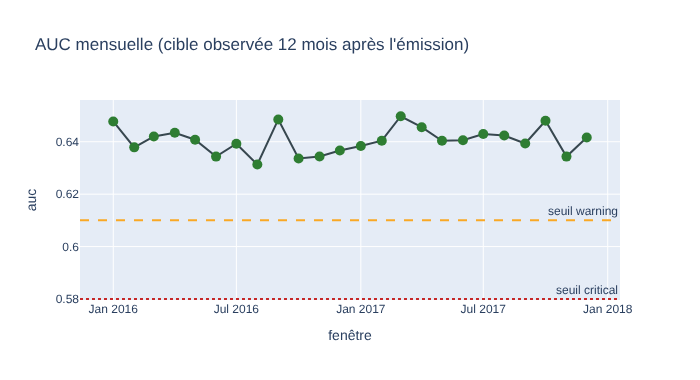

In [15]:
viz.kpi_timeseries(
    history, "auc", title="AUC mensuelle (cible observée 12 mois après l'émission)"
).show()

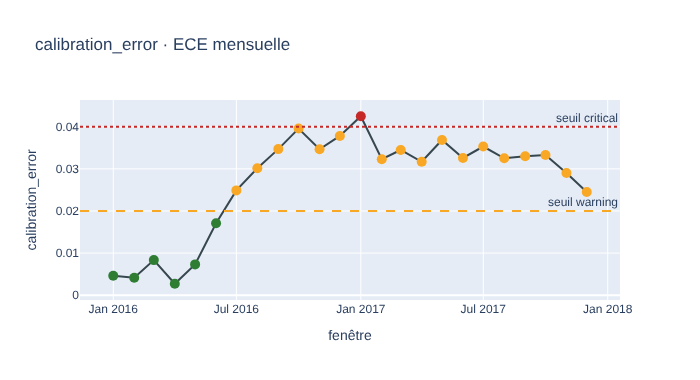

In [16]:
viz.kpi_timeseries(history, "calibration_error", title="calibration_error · ECE mensuelle").show()

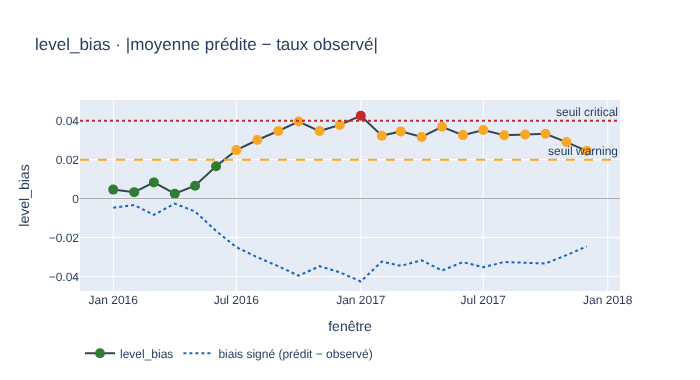

In [17]:
lb = history[history["kpi"] == "level_bias"].sort_values("window_start")
fig = viz.kpi_timeseries(
    history, "level_bias", title="level_bias · |moyenne prédite − taux observé|"
)
fig.add_trace(
    go.Scatter(
        x=pd.to_datetime(lb["window_start"]),
        y=lb["detail_signed_bias"],
        mode="lines",
        name="biais signé (prédit − observé)",
        line={"color": "#1565c0", "dash": "dot"},
    )
)
fig.add_hline(y=0, line={"color": "#9e9e9e", "width": 1})
fig.update_layout(legend={"orientation": "h", "y": -0.25})
fig.show()

In [18]:
perf_mensuelle = (
    history[history["kpi"].isin(["auc", "brier_score", "calibration_error", "level_bias"])]
    .pivot(index="mois", columns="kpi", values="value")
    .round(4)
)
signe = history[history["kpi"] == "level_bias"].set_index("mois")["detail_signed_bias"].round(4)
perf_mensuelle["biais_signe"] = signe
perf_mensuelle["taux_observe"] = (
    history[history["kpi"] == "level_bias"].set_index("mois")["detail_observed_rate"].round(4)
)
perf_mensuelle["moyenne_predite"] = (
    history[history["kpi"] == "level_bias"].set_index("mois")["detail_mean_prediction"].round(4)
)
perf_mensuelle

kpi,auc,brier_score,calibration_error,level_bias,biais_signe,taux_observe,moyenne_predite
mois,,,,,,,
2016-01,0.6477,0.1152,0.0046,0.0046,-0.0046,0.1388,0.1342
2016-02,0.6379,0.1124,0.0041,0.0033,-0.0033,0.1339,0.1306
2016-03,0.6420,0.1148,0.0083,0.0083,-0.0083,0.1377,0.1294
2016-04,0.6434,0.1131,0.0027,0.0025,-0.0025,0.1353,0.1327
2016-05,0.6408,0.1160,0.0073,0.0066,-0.0066,0.1391,0.1325
2016-06,0.6343,0.1297,0.0171,0.0166,-0.0166,0.1589,0.1423
2016-07,0.6392,0.1327,0.0249,0.0249,-0.0249,0.1640,0.1391
2016-08,0.6313,0.1368,0.0301,0.0301,-0.0301,0.1692,0.1391
2016-09,0.6485,0.1424,0.0347,0.0347,-0.0347,0.1795,0.1448


**Lecture.**

* L'**AUC est stable entre 0,63 et 0,65** sur les 24 mois : le modèle classe aussi bien en
  décembre 2017 (0,642) qu'en janvier 2016 (0,648). Un monitoring qui ne regarderait que l'AUC
  conclurait que tout va bien.
* La **calibration se dégrade dès juin 2016** : l'ECE et le biais de niveau passent de 0,005
  (janvier 2016) à 0,017 (juin), 0,025 en juillet (warning), puis **0,03-0,04 en permanence à partir
  d'août 2016**, avec un maximum de **0,040 en octobre 2016** et un dépassement du seuil critique
  (0,04) en janvier 2017 (0,0425). Fin 2017 l'ECE redescend à 0,025 (décembre 2017), toujours en
  warning.
* Le **biais signé est toujours négatif** : le modèle prédit ~13-14,5 % de remboursements anticipés
  alors que le taux observé grimpe à 16-18 %. Autrement dit, **le modèle sous-estime les
  remboursements anticipés**, donc sous-estime l'écoulement du portefeuille de prêts : les flux de
  capital projetés arrivent en réalité plus tôt, et la sensibilité au taux du bilan est mal mesurée.
* Le score de Brier suit : il dépasse 0,135 (warning) à partir d'août 2016 et touche le seuil critique
  (0,145) en octobre 2016 (0,146) puis janvier 2017 (0,145), ce qui explique les premiers criticals
  de l'historique.

## 5. La heatmap « tour de contrôle »

Une seule vue, toutes les fenêtres × tous les KPIs, colorée par sévérité : c'est la page 1 du
dashboard, celle que le métier regarde en 30 secondes.

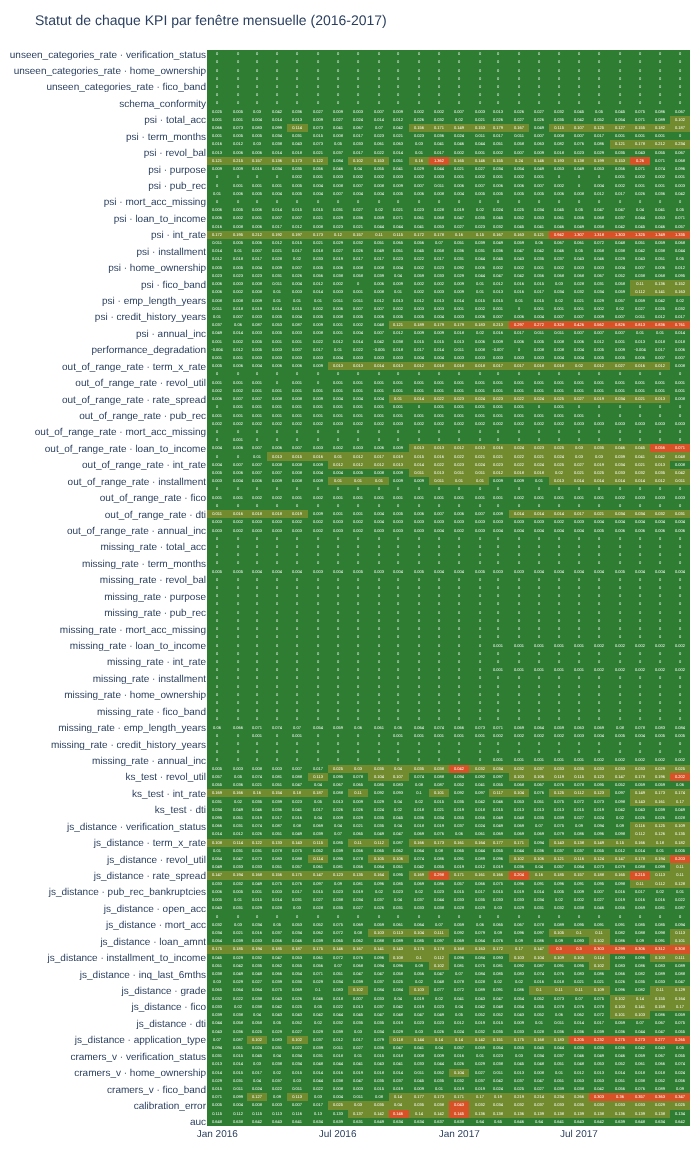

In [19]:
fig = viz.severity_heatmap(history, title="Statut de chaque KPI par fenêtre mensuelle (2016-2017)")
fig.update_layout(height=1150, margin={"l": 10, "r": 10, "t": 50, "b": 10}, font={"size": 10})
fig.show()

La heatmap fait apparaître trois « blocs » :

1. une bande orange permanente (`psi`, `js_distance`, `ks_test` sur `int_rate` et ses dérivées
   `rate_spread`, `term_x_rate`, quelques `out_of_range_rate` sur les ratios d'effort) : la dérive de
   tarification de fond ;
2. un bloc performance (`brier_score`, `calibration_error`, `level_bias`) qui passe à l'orange à
   partir de **mi-2016**, avec un épisode rouge en janvier 2017 ;
3. un bloc rouge sur la dérive de données qui s'installe à partir d'**avril 2017**
   (`application_type`) puis **juin 2017** (`int_rate`, puis `rate_spread`, `fico`, `total_acc`,
   `loan_to_income` en fin d'année).

## 6. Chronologie, décision de l'équipe et lien avec Dataiku

### Chronologie telle qu'une équipe l'aurait vécue

| date | ce que l'on voit | disponible… |
|---|---|---|
| janv. 2016 | dérive modérée de `int_rate` (warning) | immédiatement |
| sept.-oct. 2016 | `prediction_drift` monte à 0,04 : les scores se déplacent | immédiatement |
| oct. 2016 | **premier critical** : Brier 0,146 sur la cohorte d'octobre 2016 | oct. 2017 (cible connue) |
| juil. 2016 → | ECE et biais de niveau en warning, biais signé −2,5 à −4,3 points | 12 mois après chaque cohorte |
| avril 2017 | `application_type` critical : les demandes conjointes changent la population | immédiatement |
| juin 2017 | `int_rate` critical (PSI > 0,9) : nouvelle grille tarifaire | immédiatement |
| oct. 2017 | `rate_spread` critical (PSI 0,26) : l'écart au marché, moteur du prepayment, dérive à son tour | immédiatement |

### Ce que ferait l'équipe

* **Dès l'automne 2016**, sur la seule foi du `prediction_drift` et de la dérive de `int_rate` :
  ouvrir une revue de modèle, comparer la cohorte 2016 à la référence, préparer un jeu de
  recalibrage.
* **Dès que les premières cibles 2016 sont observées** (début 2017) : le biais de niveau
  négatif est confirmé. Première réponse rapide : un **recalibrage** du champion (ajustement du
  niveau par régression isotonique ou Platt sur les cohortes récentes), qui corrige l'écoulement
  projeté sans changer le classement. Il est à documenter auprès de la validation de modèles.
* **À partir d'avril-juin 2017**, avec la dérive critique de `int_rate` et `application_type` : le
  domaine d'entrée du modèle a changé, un simple recalibrage ne suffit plus. Il faut une
  **ré-estimation** sur une fenêtre de référence glissante (par exemple 2015-2017), en refaisant
  l'audit de fuite et le benchmark du notebook 02 ; le modèle ré-estimé est d'abord mis en
  **challenger** du champion en place sur les fenêtres mensuelles (règle champion-challenger du
  notebook 02, section 9) avant toute bascule ; la *model card* et la configuration de
  monitoring (`version`, seuils ancrés sur la nouvelle performance) sont mises à jour.
* Dans l'intervalle, le métier ALM est informé que l'écoulement anticipé est **sous-estimé
  d'environ 3 points** et peut appliquer un *overlay* prudentiel sur les projections.

### Lien avec Dataiku

Le dashboard décrit dans `dataiku/dashboard/dashboard_monitoring.md` reproduit exactement ces vues
avec les charts natifs de DSS, sans code, à partir du dataset `monitoring_kpis` (la table longue
que `report.to_dataframe()` produit et que l'on a lue ici dans `history.csv`) :

* **page 1 (métier)** : statut global de la dernière fenêtre, nombre de dépassements, courbe du
  biais de niveau signé avec ses bandes ±0,02 / ±0,04, AUC et calibration sur deux axes, heatmap de
  gravité ;
* **page 2** : dérive des données (PSI par feature, confronté au drift multivarié du *Model
  Evaluation Store*) ;
* **page 3** : dérive des prédictions et performance ;
* **page 4** : qualité des données.

Le scénario Dataiku mensuel (`dataiku/scenarios/alm_monitoring_scenario.json`) exécute la recette
`01_compute_alm_kpis.py` (le même `ModelMonitor.run`), alimente `monitoring_kpis`, applique le
*custom check* sur la sévérité globale et envoie l'alerte (mail / Teams) avec le PDF du dashboard.
Les figures de ce notebook sont l'équivalent Plotly de ces pages, utilisable hors Dataiku.

## Conclusion de la série

1. **Données** (notebook 01) : une cible à horizon fixe, des colonnes post-octroi bannies, une
   population qui bouge (taux, DTI, demandes conjointes) et un taux de prepayment qui monte.
2. **Modèle** (notebook 02) : un audit de fuite systématique (features métier comprises), une
   validation hors temps, un champion choisi sur la calibration et le Brier plutôt que sur la seule
   AUC, des features métier dont l'apport est modeste mais confirmé par un champion-challenger sur
   24 fenêtres, et des signes économiques vérifiés ; une AUC modeste (0,64) mais stable.
3. **Monitoring** (notebook 03) : quatorze KPIs en quatre familles ; l'AUC ne bouge pas, mais la
   dérive des prédictions, puis le biais de niveau, puis la dérive critique des données (y compris
   `rate_spread`, l'écart au marché, à l'automne 2017) racontent une histoire cohérente, datée et
   actionnable : recalibrer début 2017, ré-estimer mi-2017.

C'est le cœur de l'argument : en ALM, **surveiller le niveau** (calibration, biais) et les **signaux
précoces** (dérive des données et des scores) compte davantage que surveiller le pouvoir
discriminant.